# 03 - Exploratory Data Analysis (EDA)

## 1. Objectives
- Perform univariate, bivariate, and multivariate analysis.
- Visualize distributions across personal loan converters vs non-converters.
- Investigate correlation structure and identify dominant predictors.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

df = pd.read_csv(project_root / "data" / "raw" / "Bank_Personal_Loan_Modelling.csv")
sns.set_theme(style="whitegrid")

## 2. Univariate Distribution of Key Continuous Variables

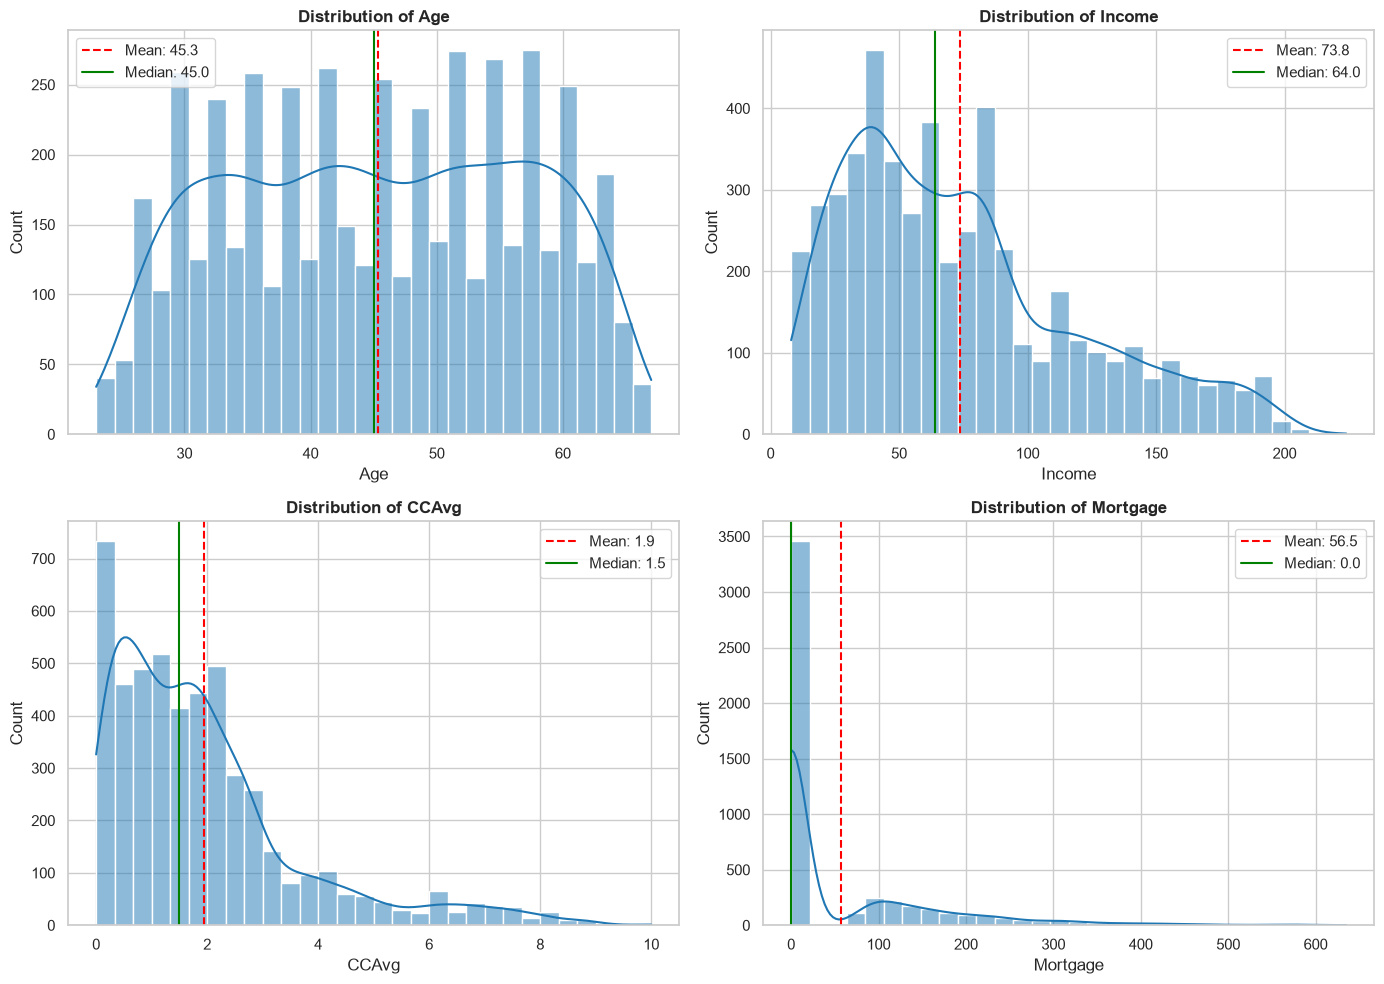

In [2]:
cont_cols = ["Age", "Income", "CCAvg", "Mortgage"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, col in enumerate(cont_cols):
    ax = axes[idx // 2, idx % 2]
    sns.histplot(df[col], kde=True, ax=ax, color="#1f77b4", bins=30)
    ax.set_title(f"Distribution of {col}", fontweight="bold")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Mean: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="green", linestyle="-", label=f"Median: {df[col].median():.1f}")
    ax.legend()

plt.tight_layout()
plt.show()

## 3. Bivariate Analysis: Income & CCAvg vs Personal Loan Acceptance

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9056\1670256482.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Personal Loan", y="Income", data=df, ax=axes[0], palette=["#2b5c8f", "#d95f02"])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9056\1670256482.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Did Not Accept (0)", "Accepted (1)"])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9056\1670256482.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Personal Loan", y="CCAvg", data=df, ax=axes[1], palette=["#2b5c8f", "#d95f02"])
C:\Users

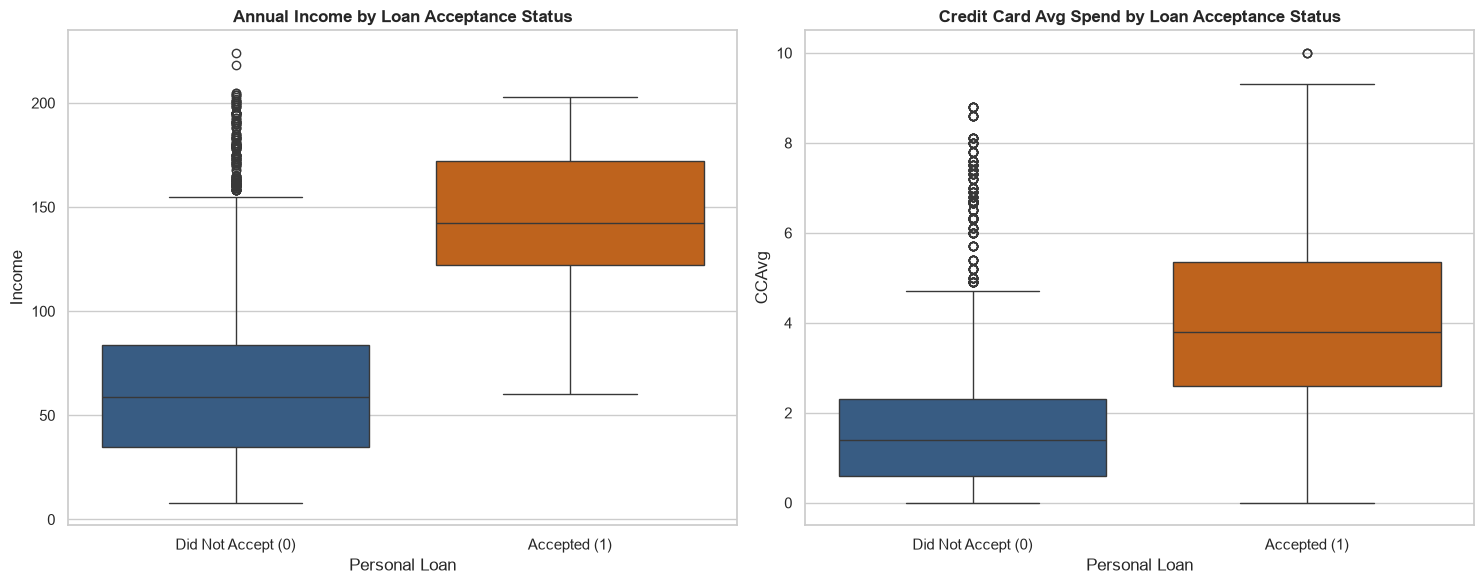

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(x="Personal Loan", y="Income", data=df, ax=axes[0], palette=["#2b5c8f", "#d95f02"])
axes[0].set_title("Annual Income by Loan Acceptance Status", fontweight="bold")
axes[0].set_xticklabels(["Did Not Accept (0)", "Accepted (1)"])

sns.boxplot(x="Personal Loan", y="CCAvg", data=df, ax=axes[1], palette=["#2b5c8f", "#d95f02"])
axes[1].set_title("Credit Card Avg Spend by Loan Acceptance Status", fontweight="bold")
axes[1].set_xticklabels(["Did Not Accept (0)", "Accepted (1)"])

plt.tight_layout()
plt.show()

## 4. Categorical Drivers: Education, Family Size, and CD Account

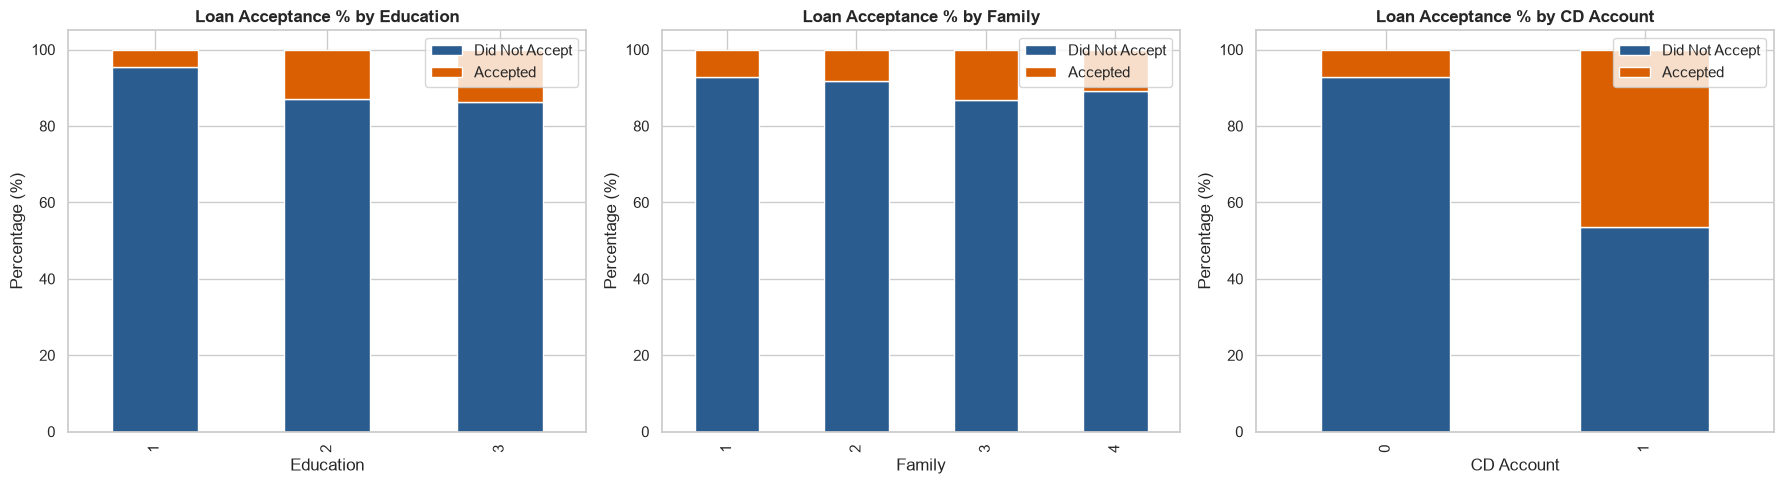

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, col in enumerate(["Education", "Family", "CD Account"]):
    crosstab_pct = pd.crosstab(df[col], df["Personal Loan"], normalize="index") * 100
    crosstab_pct.plot(kind="bar", stacked=True, ax=axes[idx], color=["#2b5c8f", "#d95f02"])
    axes[idx].set_title(f"Loan Acceptance % by {col}", fontweight="bold")
    axes[idx].set_ylabel("Percentage (%)")
    axes[idx].legend(["Did Not Accept", "Accepted"])

plt.tight_layout()
plt.show()

## 5. Correlation Heatmap

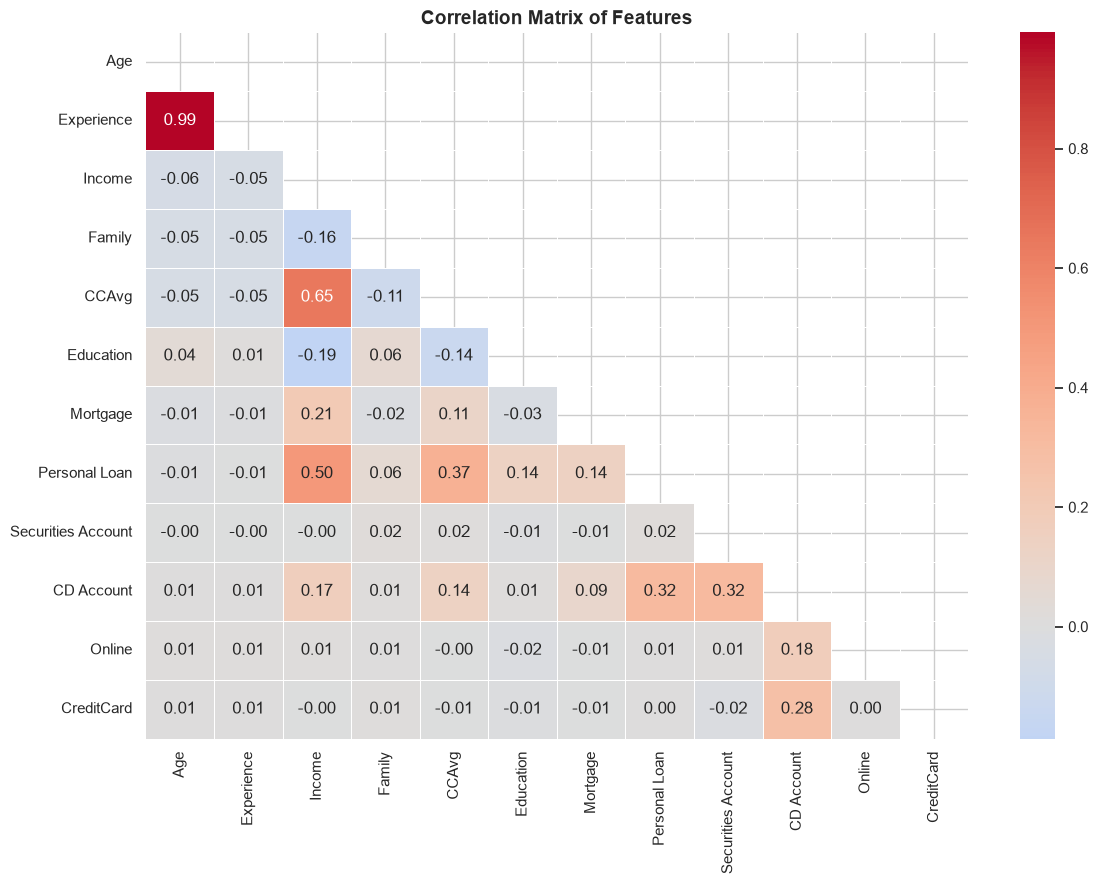

In [5]:
plt.figure(figsize=(12, 9))
corr = df.drop(columns=["ID", "ZIP Code"]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Matrix of Features", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Key EDA Findings
1. **Income** has the highest correlation with loan acceptance ($r = 0.50$). Customers accepting loans have significantly higher annual income (median ~$140k vs ~$40k).
2. **CCAvg** also shows strong positive relationship ($r = 0.37$).
3. **CD Account:** Customers with Certificate of Deposit accounts have an acceptance rate exceeding 45% (compared to ~7% for non-CD account holders).
4. **Education:** Higher education (Graduate / Professional) is strongly correlated with loan conversion.
5. **Age & Experience:** Very high collinearity ($r = 0.99$), but neither is directly correlated with loan acceptance.